# Preprocessing Katalog Gempa BMKG untuk DBSCAN

Notebook ini memproses `katalog_gempa_v2.tsv` (BMKG, via Kaggle *Earthquakes in Indonesia*) agar siap dipakai DBSCAN.
Semua keputusan berasal dari hasil EDA dan dapat diubah lewat sel **Konfigurasi**.

**Prinsip utama: tidak ada informasi yang dibuang diam-diam.**
Baris yang tidak dipakai model **ditandai** (kolom `exclusion_reason`), bukan dihapus. Satu-satunya baris yang benar-benar dihapus adalah near-duplicate, dan semuanya dicatat di log.

| Langkah | Keputusan | Alasan singkat |
|---|---|---|
| 1. Missing value | Tidak ada imputasi koordinat/magnitudo; kategori kosong menjadi `Unknown` | Mengarang nilai lokasi/magnitudo akan memalsukan data |
| 2. Duplikasi | Hapus near-duplicate (waktu + lat + lon sama), pertahankan baris yang valid | Titik kembar menggelembungkan kepadatan DBSCAN |
| 3. Fitur | `latitude`, `longitude` sebagai fitur; filter wilayah, periode, dan magnitudo kelengkapan | DBSCAN berbasis kepadatan spasial dan sangat sensitif terhadap katalog yang tidak homogen |
| 4. Kategorikal | Tidak di-encode, hanya dirapikan (`BMG` menjadi `BMKG`) | Bukan fitur clustering; one-hot hanya merusak jarak |
| 5. Skala | Konversi ke radian (haversine) dan opsional Kartesian 3D km; **bukan** StandardScaler | Z-score mendistorsi geometri bumi (dibuktikan di notebook) |
| 6. Perbandingan | Tabel metrik, waterfall baris, dan grafik sebelum vs sesudah | Menunjukkan apa yang berubah dan apa yang dipertahankan |

**Cara pakai di Colab:** jalankan sel dari atas. Jika `archive.zip` belum ada di `/content`, sel pemuatan akan meminta Anda mengunggahnya.

## 1. Impor pustaka

In [1]:
import os, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr
from matplotlib.ticker import MaxNLocator
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics.pairwise import haversine_distances
from sklearn.neighbors import BallTree

try:
    from IPython.display import display
except ImportError:
    display = print

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
print("Berjalan di Google Colab:", IN_COLAB)

Berjalan di Google Colab: True


## 2. Konfigurasi

Semua parameter ada di satu tempat. Nilai default berasal dari EDA dan analisis kelengkapan katalog di Langkah 3.

In [2]:
# --- Lokasi data (kosongkan agar dicari otomatis / diminta unggah di Colab) ---
DATA_PATH = None            # contoh: "/content/archive.zip" atau "/content/drive/MyDrive/archive.zip"
TSV_NAME  = "katalog_gempa_v2.tsv"
OUT_DIR   = "/content/hasil_preprocessing" if IN_COLAB else "./hasil_preprocessing"
os.makedirs(OUT_DIR, exist_ok=True)

# --- Wilayah studi: kotak lintang/bujur kepulauan Indonesia dan sekitarnya ---
LAT_RANGE = (-11.0, 6.0)
LON_RANGE = (94.0, 142.0)
EXCLUDE_LOCATION_KEYWORDS = []   # opsional, mis. ["Philippines", "P.N.G."]; default: tidak ada

# --- Periode dan kelengkapan katalog (dasar: analisis di Langkah 3) ---
START_DATE   = "2010-01-01"      # 2008-2009 parsial / banyak hari data hilang
MC_THRESHOLD = 4.5               # magnitudo kelengkapan (Mc) yang dipakai untuk set model

# --- Kualitas data ---
MAX_DEPTH_KM    = 800            # kedalaman gempa nyata tidak melebihi ~700-750 km
MAX_AZIMUTH_GAP = None           # None = tidak memfilter; mis. 270 untuk membuang lokasi yang sangat tidak pasti

EARTH_RADIUS_KM = 6371.0088
RANDOM_STATE    = 42

## 3. Memuat data dan potret awal ("sebelum")

Data dibaca langsung dari `archive.zip` tanpa perlu ekstraksi manual. Tabel mentah `raw` **tidak pernah diubah**; semua proses bekerja pada salinan.

In [3]:
def locate_data(path=None):
    candidates = [path, "/content/archive.zip", "/content/" + TSV_NAME, "archive.zip", TSV_NAME,
                  "/content/drive/MyDrive/archive.zip", "/content/drive/MyDrive/" + TSV_NAME]
    for c in candidates:
        if c and os.path.exists(c):
            return c
    if IN_COLAB:
        from google.colab import files
        print("File tidak ditemukan. Silakan unggah archive.zip (atau katalog_gempa_v2.tsv)...")
        uploaded = files.upload()
        return next(iter(uploaded))
    raise FileNotFoundError("Isi DATA_PATH dengan lokasi archive.zip atau katalog_gempa_v2.tsv")

def read_catalog(path):
    if path.lower().endswith(".zip"):
        with zipfile.ZipFile(path) as z:
            name = next(n for n in z.namelist() if n.endswith(TSV_NAME))
            with z.open(name) as f:
                return pd.read_csv(f, sep="\t", low_memory=False)
    return pd.read_csv(path, sep="\t", low_memory=False)

path = locate_data(DATA_PATH)
raw = read_catalog(path)
print("Sumber :", path)
print("Bentuk :", raw.shape)

CORE = ["eventID", "datetime", "latitude", "longitude", "magnitude", "mag_type",
        "depth", "phasecount", "azimuth_gap", "location", "agency"]

def snapshot(d, n_cols):
    """Ringkasan metrik kualitas untuk perbandingan sebelum vs sesudah."""
    yr = d.groupby(d["datetime"].dt.year).size()
    yr_full = yr.loc[2010:2025]
    mag = d["magnitude"].dropna()
    return {
        "Jumlah baris": len(d),
        "Jumlah kolom": n_cols,
        "Sel kosong pada 11 kolom inti": int(d[CORE].isna().sum().sum()),
        "Baris duplikat penuh": int(d.duplicated().sum()),
        "Near-duplicate (waktu+lat+lon sama)": int(d.duplicated(["datetime", "latitude", "longitude"]).sum()),
        "Rentang latitude": f"{d.latitude.min():.1f} s.d. {d.latitude.max():.1f}",
        "Rentang longitude": f"{d.longitude.min():.1f} s.d. {d.longitude.max():.1f}",
        "Rentang waktu": f"{d.datetime.min():%Y-%m-%d} s.d. {d.datetime.max():%Y-%m-%d}",
        "Magnitudo min / median / maks": f"{mag.min():.2f} / {mag.median():.2f} / {mag.max():.2f}",
        "Kedalaman maks (km)": float(d.depth.max()),
        "Kejadian di tepat 10 km (%)": round((d.depth == 10).mean() * 100, 1),
        "Jumlah kategori mag_type": int(d.mag_type.nunique(dropna=False)),
        "Nilai unik agency": ", ".join(sorted(map(str, d.agency.unique()))),
        "CV jumlah kejadian per tahun (2010-2025)": round(yr_full.std() / yr_full.mean(), 2),
    }

before = raw[CORE].copy()
before["datetime"] = pd.to_datetime(before["datetime"], utc=True, format="ISO8601")  # hanya untuk statistik
snap_before = snapshot(before, raw.shape[1])
del before
pd.Series(snap_before, name="Sebelum").to_frame()

File tidak ditemukan. Silakan unggah archive.zip (atau katalog_gempa_v2.tsv)...


Saving archive.zip to archive.zip
Sumber : archive.zip
Bentuk : (176384, 37)


,Sebelum
Jumlah baris,176384
Jumlah kolom,37
Sel kosong pada 11 kolom inti,6778
Baris duplikat penuh,0
Near-duplicate (waktu+lat+lon sama),2
Rentang latitude,-77.0 s.d. 87.6
Rentang longitude,-180.0 s.d. 180.0
Rentang waktu,2008-11-01 s.d. 2026-07-14
Magnitudo min / median / maks,0.19 / 3.64 / 8.75
Kedalaman maks (km),90000.0


## 4. Langkah 1 - Penanganan missing value

**Temuan EDA:** `magnitude` dan `mag_type` kosong 1.405 baris, `agency` kosong 3.936 baris (semuanya 2008-2009), `location` 28 baris, `azimuth_gap` 4 baris, dan blok mekanisme fokal (26 kolom) kosong rata-rata 95,6%.

**Keputusan dan alasan:**

| Kolom | Penanganan | Alasan |
|---|---|---|
| `latitude`, `longitude`, `depth`, `datetime` | Wajib lengkap (di-`assert`) | Sudah 0% kosong; jika ada yang kosong, baris tidak bisa dipakai |
| `magnitude` | **Tidak diimputasi.** Diberi penanda `magnitude_missing` | Magnitudo hanya dipakai sebagai filter kelengkapan. Mengisinya dengan median akan memalsukan data. Baris tanpa magnitudo tidak bisa dibuktikan memenuhi ambang Mc, sehingga dikeluarkan dari set model namun **tetap disimpan** |
| `mag_type`, `agency`, `location` | Diisi `Unknown` | Bukan fitur numerik; label eksplisit lebih jujur daripada menebak modus |
| `azimuth_gap` | Dibiarkan `NaN` | Hanya metadata kualitas (4 baris); imputasi tidak diperlukan |
| Blok FM (26 kolom) | Tidak dibawa ke tabel kerja; diganti satu penanda `has_focal_mechanism` | 95,6% kosong dan bukan fitur spasial. Informasi "gempa ini punya mekanisme fokal" tetap terjaga |

In [4]:
df = raw[CORE].copy()
df["has_focal_mechanism"] = raw["datetimeFM"].notna()

# datetime: format campuran (ada 4 baris tanpa mikrodetik) -> ISO8601 fleksibel
df["datetime"] = pd.to_datetime(df["datetime"], utc=True, format="ISO8601")

# --- Laporan missing value (sebelum penanganan) ---
miss_before = pd.DataFrame({"jumlah_kosong": df[CORE].isna().sum(),
                            "persen": (df[CORE].isna().mean() * 100).round(2)})
print("Missing value SEBELUM penanganan:")
display(miss_before[miss_before.jumlah_kosong > 0])

# --- Kolom wajib lengkap ---
for c in ["eventID", "datetime", "latitude", "longitude", "depth"]:
    assert df[c].notna().all(), f"Kolom {c} memiliki nilai kosong!"

# --- Magnitudo: jangan diimputasi, cukup beri penanda ---
df["magnitude_missing"] = df["magnitude"].isna()

# --- Kategori: isi label eksplisit ---
for c in ["mag_type", "agency", "location"]:
    df[c] = df[c].fillna("Unknown")

miss_after = df[CORE].isna().sum()
print("\nMissing value SESUDAH penanganan (kolom yang masih kosong):")
display(miss_after[miss_after > 0].to_frame("jumlah_kosong"))

Missing value SEBELUM penanganan:


,jumlah_kosong,persen
magnitude,1405,0.80
mag_type,1405,0.80
azimuth_gap,4,0.00
location,28,0.02
agency,3936,2.23



Missing value SESUDAH penanganan (kolom yang masih kosong):


,jumlah_kosong
magnitude,1405
azimuth_gap,4


## 5. Langkah 2 - Penanganan duplikasi

**Temuan EDA:** tidak ada baris identik, tetapi ada 2 pasang *near-duplicate* (waktu, latitude, longitude sama persis). Salah satunya (`bmg2012vrrg`) bahkan memiliki `depth` = 90.000 km, salinan yang salah dari `bmg2012vrrd` (90 km).

**Aturan:** untuk setiap grup near-duplicate, pertahankan satu baris dengan prioritas (1) kedalaman masuk akal, (2) magnitudo terisi, (3) `eventID` terkecil agar deterministik.

**Alasan:** dua titik kembar menggandakan kepadatan di satu lokasi, padahal DBSCAN menilai klaster dari jumlah tetangga. Gempa yang berbeda dengan koordinat sama tetapi **waktu berbeda** *tidak* dihapus karena itu kejadian nyata yang berbeda (gempa susulan di titik yang sama).

In [5]:
removed_log = []   # catatan semua baris yang benar-benar dihapus

# --- 2a. Duplikat penuh ---
exact_mask = df.duplicated()
print("Duplikat penuh :", int(exact_mask.sum()))
if exact_mask.any():
    removed_log.append(df[exact_mask].assign(removal_reason="duplikat penuh"))
    df = df[~exact_mask]

# --- 2b. Near-duplicate: waktu + lat + lon sama ---
key = ["datetime", "latitude", "longitude"]
grp = df[df.duplicated(key, keep=False)].sort_values(key)
print("Near-duplicate :", len(grp), "baris dalam", grp.groupby(key).ngroups, "grup")
display(grp[["eventID", "datetime", "latitude", "longitude", "magnitude", "mag_type", "depth", "agency"]])

df["_depth_bad"] = df["depth"] > MAX_DEPTH_KM
ordered = df.sort_values(["_depth_bad", "magnitude_missing", "eventID"])
drop_idx = ordered.index[ordered.duplicated(key, keep="first")]
removed_log.append(df.loc[drop_idx].assign(removal_reason="near-duplicate (waktu+lat+lon sama)"))
df = df.drop(index=drop_idx)

# --- 2c. Kedalaman mustahil yang BUKAN duplikat: tandai NaN, jangan hapus kejadian ---
bad_depth = df["depth"] > MAX_DEPTH_KM
print("Kedalaman > %d km yang tersisa setelah dedup: %d" % (MAX_DEPTH_KM, bad_depth.sum()))
df.loc[bad_depth, "depth"] = np.nan
df = df.drop(columns="_depth_bad")

removed_log = pd.concat(removed_log) if removed_log else pd.DataFrame()
print("\nBaris dihapus:", len(removed_log), "| baris tersisa:", len(df))
display(removed_log[["eventID", "datetime", "latitude", "longitude", "depth", "removal_reason"]])

Duplikat penuh : 0
Near-duplicate : 4 baris dalam 2 grup


,eventID,datetime,latitude,longitude,magnitude,mag_type,depth,agency
25565,bmg2012vrrd,2012-11-04 12:12:59.130487+00:00,-22.099361,171.677414,5.300036,M,90,BMG
25566,bmg2012vrrg,2012-11-04 12:12:59.130487+00:00,-22.099361,171.677414,5.300036,M,90000,BMG
103257,bmg2021ijpa,2021-04-30 02:06:13.567985+00:00,-29.551546,-177.234680,5.733344,M,32,BMKG
103258,bmg2021ijpb,2021-04-30 02:06:13.567985+00:00,-29.551546,-177.234680,5.733263,M,32,BMKG


Kedalaman > 800 km yang tersisa setelah dedup: 0

Baris dihapus: 2 | baris tersisa: 176382


,eventID,datetime,latitude,longitude,depth,removal_reason
103258,bmg2021ijpb,2021-04-30 02:06:13.567985+00:00,-29.551546,-177.234680,32,near-duplicate (waktu+lat+lon sama)
25566,bmg2012vrrg,2012-11-04 12:12:59.130487+00:00,-22.099361,171.677414,90000,near-duplicate (waktu+lat+lon sama)


## 6. Langkah 3 - Pemilihan fitur dan penyaringan

### 3a. Fitur untuk clustering
Hanya **`latitude` dan `longitude`** yang menjadi fitur utama. Alasan: DBSCAN mendefinisikan klaster dari kepadatan titik dalam ruang jarak, dan pertanyaan studi kasus bersifat spasial (di mana gempa mengelompok). Kolom lain **dipertahankan sebagai metadata** untuk interpretasi klaster:

| Kolom | Peran | Mengapa bukan fitur |
|---|---|---|
| `depth` | Opsional (varian 3D) | 32% kejadian bernilai tepat 10 km (indikasi kedalaman default) dan sangat miring |
| `magnitude`, `mag_type` | Filter kelengkapan + profil klaster | Skala magnitudo bercampur (rata-rata `MLv` 3,3 vs `mb` 4,9) sehingga tidak sebanding |
| `phasecount`, `azimuth_gap` | Indikator kualitas | Mengukur kualitas pengukuran, bukan lokasi |
| `location`, `agency`, `eventID` | Label | Teks/ID |
| `datetime` | Pembagi periode | Waktu bukan dimensi jarak spasial |

### 3b. Penyaringan: ditandai, bukan dihapus
Tiga masalah homogenitas dari EDA ditangani dengan **flag**:
1. **Wilayah** - kotak lintang -11..6 dan bujur 94..142. Batas ini tektonik, bukan politik; kejadian di perbatasan (mis. Laut Maluku-Mindanao) tetap masuk agar klaster tidak terpotong garis negara.
2. **Periode** - mulai 2010. Tahun 2008 hanya Nov-Des dan 2009 memiliki hari-hari data hilang serta `agency` kosong.
3. **Kelengkapan magnitudo (Mc)** - katalog mendeteksi gempa kecil makin banyak seiring waktu (median magnitudo turun dari ~4,6 menjadi ~3,0; lonjakan `MLv` 2025). Jika semua magnitudo dipakai, daerah dan tahun dengan jaringan deteksi padat tampak "lebih padat" secara artifisial. Sel berikut menguji ambang yang tepat dengan data, bukan tebakan.

Kelengkapan per tahun (di dalam wilayah studi):


,n_semua,Mc_MAXC,n_M>=4.0,n_M>=4.5,n_M>=5.0
year,,,,,
2009,3168.0,4.55,1823.0,1062.0,340.0
2010,6212.0,3.65,2616.0,1289.0,290.0
2011,4474.0,3.85,1885.0,954.0,233.0
2012,6623.0,3.45,2217.0,1020.0,226.0
2013,3542.0,3.75,1398.0,669.0,137.0
2014,4662.0,3.95,1819.0,861.0,204.0
2015,5313.0,3.95,1874.0,902.0,167.0
2016,5644.0,3.55,1752.0,757.0,104.0
2017,7131.0,3.65,1835.0,697.0,89.0



b-value per periode (stabil antar-periode = homogen):


,b untuk M>=3.5,b untuk M>=4.0,b untuk M>=4.5,b untuk M>=5.0
2010-2016,0.59,0.82,1.29,1.41
2017-2024,0.70,0.93,1.31,1.12
2025-2026,0.78,1.03,1.37,0.95



Sensitivitas ambang magnitudo:


,baris_model,CV_per_tahun,rentang_b
ambang,,,
M>=3.5,61603,0.23,0.59-0.78
M>=4.0,34335,0.18,0.82-1.03
M>=4.5,14347,0.21,1.29-1.37
M>=5.0,2847,0.34,0.95-1.41


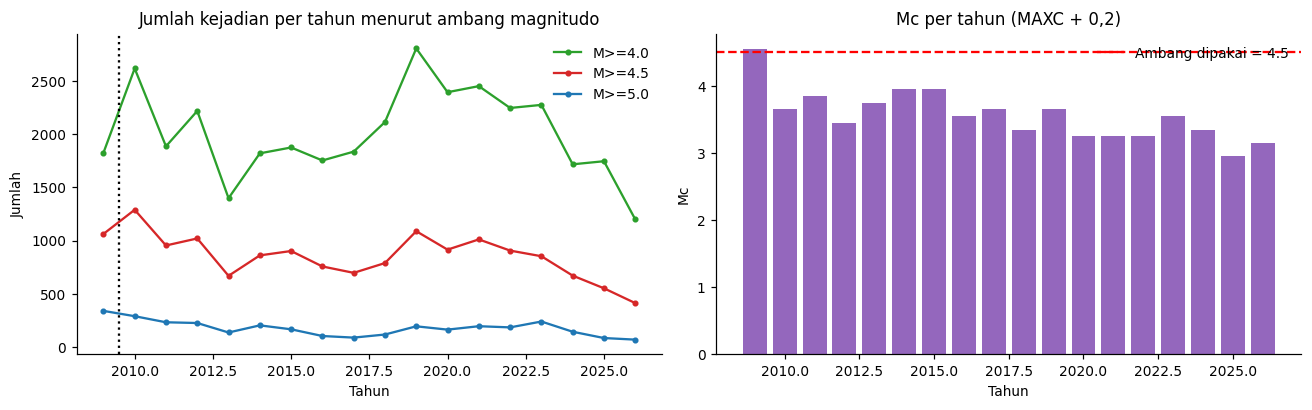

In [6]:
# ---------- Analisis kelengkapan katalog (di dalam wilayah studi) ----------
in_region_tmp = df["latitude"].between(*LAT_RANGE) & df["longitude"].between(*LON_RANGE)
reg = df[in_region_tmp].copy()
reg["year"] = reg["datetime"].dt.year

def mc_maxc(m, bin_w=0.1, min_n=200):
    """Mc metode Maximum Curvature + koreksi 0,2."""
    m = m.dropna()
    if len(m) < min_n:
        return np.nan
    edges = np.arange(np.floor(m.min() * 10) / 10, m.max() + bin_w, bin_w)
    counts, edges = np.histogram(m, bins=edges)
    return round(edges[np.argmax(counts)] + bin_w / 2 + 0.2, 2)

def b_value(m, mc):
    """Estimasi b-value Aki (magnitudo kontinu). b stabil antar-periode = katalog lengkap di atas mc."""
    x = m.dropna()
    x = x[x >= mc]
    return round(np.log10(np.e) / (x.mean() - mc), 2)

comp = reg[reg.year >= 2009].groupby("year").apply(lambda g: pd.Series({
    "n_semua": len(g),
    "Mc_MAXC": mc_maxc(g["magnitude"]),
    "n_M>=4.0": int((g.magnitude >= 4.0).sum()),
    "n_M>=4.5": int((g.magnitude >= 4.5).sum()),
    "n_M>=5.0": int((g.magnitude >= 5.0).sum()),
}))
print("Kelengkapan per tahun (di dalam wilayah studi):")
display(comp)

periods = {"2010-2016": (2010, 2016), "2017-2024": (2017, 2024), "2025-2026": (2025, 2026)}
bt = pd.DataFrame({f"b untuk M>={th}": {lab: b_value(reg[(reg.year >= a) & (reg.year <= z)].magnitude, th)
                                         for lab, (a, z) in periods.items()} for th in [3.5, 4.0, 4.5, 5.0]})
print("\nb-value per periode (stabil antar-periode = homogen):")
display(bt)

# ---------- Sensitivitas ambang ----------
rows = []
for th in [3.5, 4.0, 4.5, 5.0]:
    g = reg[(reg.datetime >= pd.Timestamp(START_DATE, tz="UTC")) & (reg.magnitude >= th)]
    yc = g.groupby(g.datetime.dt.year).size().loc[2010:2025]
    rows.append({"ambang": f"M>={th}", "baris_model": len(g), "CV_per_tahun": round(yc.std() / yc.mean(), 2),
                 "rentang_b": f"{bt[f'b untuk M>={th}'].min()}-{bt[f'b untuk M>={th}'].max()}"})
print("\nSensitivitas ambang magnitudo:")
display(pd.DataFrame(rows).set_index("ambang"))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for th, c in [(4.0, "#2ca02c"), (4.5, "#d62728"), (5.0, "#1f77b4")]:
    s = comp[f"n_M>={th}"]; ax[0].plot(s.index, s.values, marker="o", ms=3, label=f"M>={th}", color=c)
ax[0].axvline(int(START_DATE[:4]) - 0.5, color="k", ls=":"); ax[0].set_title("Jumlah kejadian per tahun menurut ambang magnitudo")
ax[0].set_xlabel("Tahun"); ax[0].set_ylabel("Jumlah"); ax[0].legend(frameon=False)
ax[1].bar(comp.index, comp["Mc_MAXC"], color="#9467bd"); ax[1].axhline(MC_THRESHOLD, color="r", ls="--", label=f"Ambang dipakai = {MC_THRESHOLD}")
ax[1].set_title("Mc per tahun (MAXC + 0,2)"); ax[1].set_xlabel("Tahun"); ax[1].set_ylabel("Mc"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/analisis_kelengkapan_katalog.png", dpi=130); plt.show()

**Cara membaca hasil:** pada M>=4,5, b-value stabil antar-periode, sedangkan pada M>=4,0 b-value bergeser mengikuti perubahan jaringan deteksi (katalog belum seragam). Jumlah kejadian per tahun pada set model juga lebih seragam dibanding data mentah (koefisien variasi 0,21 vs 0,38; lihat tabel perbandingan di Langkah 6). Karena itu `MC_THRESHOLD = 4.5` dipakai sebagai default. M>=4,0 tetap layak dijadikan analisis sensitivitas (ubah di sel Konfigurasi).

In [7]:
# ---------- Flag penyaringan (BARIS TIDAK DIHAPUS) ----------
df["in_region"] = df["latitude"].between(*LAT_RANGE) & df["longitude"].between(*LON_RANGE)
if EXCLUDE_LOCATION_KEYWORDS:
    pat = "|".join(EXCLUDE_LOCATION_KEYWORDS)
    df["in_region"] &= ~df["location"].str.contains(pat, case=False, na=False)

df["in_period"]   = df["datetime"] >= pd.Timestamp(START_DATE, tz="UTC")
df["is_complete"] = df["magnitude"] >= MC_THRESHOLD            # NaN -> False
df["quality_ok"]  = True if MAX_AZIMUTH_GAP is None else (df["azimuth_gap"].isna() | (df["azimuth_gap"] <= MAX_AZIMUTH_GAP))

df["exclusion_reason"] = np.select(
    [~df.in_region, ~df.in_period, df.magnitude_missing, ~df.is_complete, ~df.quality_ok],
    ["di luar wilayah studi", "sebelum periode studi", "magnitudo kosong",
     f"magnitudo < {MC_THRESHOLD}", "azimuth_gap terlalu besar"],
    default="dipakai untuk model")
df["use_for_model"] = df["exclusion_reason"].eq("dipakai untuk model")

print("Alasan pengecualian (urutan evaluasi = prioritas):")
display(df["exclusion_reason"].value_counts().to_frame("jumlah"))

# ---------- Waterfall jumlah baris ----------
steps = [("Data mentah", len(raw)),
         ("Setelah hapus duplikat", len(df)),
         ("Di dalam wilayah studi", int(df.in_region.sum())),
         (f"Dan periode >= {START_DATE}", int((df.in_region & df.in_period).sum())),
         ("Dan magnitudo terisi", int((df.in_region & df.in_period & ~df.magnitude_missing).sum())),
         (f"Dan magnitudo >= {MC_THRESHOLD}", int((df.in_region & df.in_period & df.is_complete).sum())),
         ("Set model akhir", int(df.use_for_model.sum()))]
waterfall = pd.DataFrame(steps, columns=["tahap", "baris_tersisa"])
waterfall["baris_keluar"] = (-waterfall["baris_tersisa"].diff()).fillna(0).astype(int)
display(waterfall)

# ---------- Pemeriksaan: informasi penting tidak hilang ----------
big = df[df.in_region & df.in_period & (df.magnitude >= 6.0)]
print(f"\nGempa M>=6,0 di wilayah & periode studi: {len(big)} | masuk set model: {int(big.use_for_model.sum())}  (harus sama)")
assert len(big) == int(big.use_for_model.sum()), "Ada gempa besar yang terbuang!"

# ---------- Laporan celah data: hari tanpa satu pun kejadian di katalog ----------
all_days = pd.date_range(pd.Timestamp(START_DATE, tz="UTC"), df.datetime.max().normalize(), freq="D")
have = pd.DatetimeIndex(df["datetime"].dt.normalize().unique())
gap_days = pd.Series(all_days.difference(have))
if len(gap_days):
    runs = gap_days.groupby((gap_days.diff().dt.days != 1).cumsum()).agg(["min", "max", "count"])
    print(f"\nHari tanpa data sejak {START_DATE}: {len(gap_days)} dari {len(all_days)} hari. Celah terpanjang:")
    display(runs.sort_values("count", ascending=False).head(5).assign(min=lambda x: x["min"].dt.date, max=lambda x: x["max"].dt.date))
else:
    print("Tidak ada hari tanpa data.")
print("Catatan: celah dilaporkan, tidak dihapus/diisi. Hari tanpa data bukan berarti tanpa gempa.")

Alasan pengecualian (urutan evaluasi = prioritas):


,jumlah
exclusion_reason,
magnitudo < 4.5,124598
di luar wilayah studi,33194
dipakai untuk model,14347
sebelum periode studi,3341
magnitudo kosong,902


,tahap,baris_tersisa,baris_keluar
0,Data mentah,176384,0
1,Setelah hapus duplikat,176382,2
2,Di dalam wilayah studi,143188,33194
3,Dan periode >= 2010-01-01,139847,3341
4,Dan magnitudo terisi,138945,902
5,Dan magnitudo >= 4.5,14347,124598
6,Set model akhir,14347,0



Gempa M>=6,0 di wilayah & periode studi: 210 | masuk set model: 210  (harus sama)

Hari tanpa data sejak 2010-01-01: 75 dari 6039 hari. Celah terpanjang:


,min,max,count
8,2013-07-20,2013-08-11,23
9,2013-08-13,2013-08-31,19
10,2018-11-22,2018-11-28,7
2,2013-01-08,2013-01-12,5
6,2013-07-11,2013-07-15,5


Catatan: celah dilaporkan, tidak dihapus/diisi. Hari tanpa data bukan berarti tanpa gempa.


## 7. Langkah 4 - Penanganan data kategorikal

**Kolom kategorikal:** `mag_type`, `agency`, `location`, `eventID`.

**Keputusan:** **tidak ada one-hot / label encoding**, karena tidak satu pun menjadi fitur clustering. One-hot pada `location` (557 nilai) akan menambah ratusan dimensi biner yang merusak jarak Euclid/haversine, dan label encoding menciptakan urutan palsu antar-kategori.

Yang dilakukan hanyalah **merapikan label** agar bisa dipakai untuk profil klaster nanti:
- `agency`: `BMG` adalah nama lama BMKG (institusi yang sama), jadi disatukan menjadi `BMKG`. Nilai asli disimpan di `agency_raw`.
- `mag_type`: **tidak digabung**, karena skalanya benar-benar berbeda (`mb`, `Mw`, `MLv`, ...); menggabungkannya akan menghilangkan informasi.
- Ketiganya diubah ke tipe `category` (hemat memori, valid untuk `groupby` profil klaster).

In [8]:
df["agency_raw"] = df["agency"]
df["agency"] = df["agency"].replace({"BMG": "BMKG"})
for c in ["mag_type", "agency", "location"]:
    df[c] = df[c].astype("category")

print("agency  - sebelum:", df["agency_raw"].value_counts().to_dict())
print("agency  - sesudah:", df["agency"].value_counts().to_dict())
print("\nmag_type pada set model:")
mt = df.loc[df.use_for_model, "mag_type"].value_counts()
display(mt[mt > 0].to_frame("jumlah"))
print("Wilayah (location) terbanyak pada set model:")
display(df.loc[df.use_for_model, "location"].value_counts().head(8).to_frame("jumlah"))

agency  - sebelum: {'BMKG': 122924, 'BMG': 49522, 'Unknown': 3936}
agency  - sesudah: {'BMKG': 172446, 'Unknown': 3936}

mag_type pada set model:


,jumlah
mag_type,
M,5699
mb,3097
MLv,2854
Mw,1377
Mw(mB),1298
mB,11
Mwp,6
Mw(Mwp),4
Mjma,1


Wilayah (location) terbanyak pada set model:


,jumlah
location,
Banda Sea,2416
Northern Molucca Sea,893
"Talaud Islands, Indonesia",834
"Southern Sumatra, Indonesia",818
"Halmahera, Indonesia",724
"Minahassa Peninsula, Sulawesi",670
"Mindanao, Philippines",668
"Irian Jaya Region, Indonesia",605


## 8. Langkah 5 - Standardisasi / normalisasi

**Pertanyaan kuncinya: skala apa yang sesuai untuk koordinat bumi?**

`StandardScaler` dan `MinMaxScaler` lazim untuk fitur bersatuan berbeda (mis. umur dan gaji). Tetapi latitude dan longitude **satuannya sama (derajat) dan ruangnya geometri bumi**. Menskalakan masing-masing sumbu dengan simpangan baku/rentangnya sendiri akan **meregangkan satu sumbu relatif terhadap yang lain**, sehingga jarak antar-titik tidak lagi mencerminkan jarak sebenarnya. Pada data ini, simpangan baku bujur kira-kira 2,5 kali lintang, sehingga z-score membuat 1 derajat lintang "bernilai" 2,5 kali 1 derajat bujur.

**Metode yang dipakai (tanpa mengubah geometri):**
- **Fitur utama - `X_haversine`**: (lat, lon) dalam **radian**, dipakai dengan `DBSCAN(metric="haversine")`. Jarak yang dihitung adalah jarak busur bumi; `eps` cukup dikonversi dari km ke radian (`eps_rad = eps_km / 6371`).
- **Varian 3D - `X_3d_km`**: koordinat Kartesian (x, y, z) dalam **km** dari pusat bumi dengan jari-jari `R - depth`. Jarak Euclid pada ruang ini adalah jarak lurus antar-hiposenter, sehingga kedalaman bergabung dengan lat/lon dalam satuan yang sama tanpa skala buatan.

Sel berikut **membuktikan** pilihan ini: membandingkan seberapa setia tiap skala terhadap jarak bumi sebenarnya.

> Catatan jujur: derajat mentah (tanpa skala apa pun) ternyata hampir setia di wilayah ini karena letaknya dekat ekuator. Haversine tetap dipilih karena `eps` dapat dinyatakan dalam **km** (mudah ditafsirkan dan dijustifikasi secara geofisika) dan tetap benar jika wilayah studi diperluas ke lintang tinggi. Yang jelas keliru adalah `StandardScaler`/`MinMaxScaler`.

In [9]:
model = df[df.use_for_model].sort_values("datetime").reset_index(drop=True)

lat_r = np.radians(model["latitude"].to_numpy())
lon_r = np.radians(model["longitude"].to_numpy())

# --- Fitur utama: radian untuk haversine ---
X_haversine = np.column_stack([lat_r, lon_r])          # urutan (lat, lon) sesuai scikit-learn

def eps_km_to_rad(eps_km):
    return eps_km / EARTH_RADIUS_KM

# --- Varian 3D: Kartesian km, kedalaman ikut dihitung ---
r = EARTH_RADIUS_KM - model["depth"].to_numpy()
X_3d_km = np.column_stack([r * np.cos(lat_r) * np.cos(lon_r),
                           r * np.cos(lat_r) * np.sin(lon_r),
                           r * np.sin(lat_r)])

assert np.isfinite(X_haversine).all() and np.isfinite(X_3d_km).all()
print("X_haversine :", X_haversine.shape, "(radian)")
print("X_3d_km     :", X_3d_km.shape, "(km)")
print("Contoh eps 25 km =", round(eps_km_to_rad(25), 6), "radian")

# ---------- Bukti: kesetiaan jarak berbagai skala ----------
rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(model), size=min(2000, len(model)), replace=False)
S = model.iloc[idx]
deg = S[["latitude", "longitude"]].to_numpy()

true_km = haversine_distances(np.radians(deg)) * EARTH_RADIUS_KM       # jarak bumi sebenarnya
iu = np.triu_indices(len(S), k=1)

la, lo = np.radians(deg[:, 0]), np.radians(deg[:, 1])
surface_xyz = EARTH_RADIUS_KM * np.column_stack([np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)])

candidates = {
    "Derajat mentah (tanpa skala)": deg,
    "StandardScaler (z-score)":     StandardScaler().fit_transform(deg),
    "MinMaxScaler":                 MinMaxScaler().fit_transform(deg),
    "Kartesian 3D km (chord)":      surface_xyz,
}

def knn_overlap(D, true_D, k=5):
    D = D.copy(); T = true_D.copy()
    np.fill_diagonal(D, np.inf); np.fill_diagonal(T, np.inf)
    a = np.argpartition(D, k, axis=1)[:, :k]; b = np.argpartition(T, k, axis=1)[:, :k]
    return np.mean([len(set(x) & set(y)) / k for x, y in zip(a, b)])

res = []
for name, X in candidates.items():
    d = pdist(X)
    res.append({"metode": name,
                "Spearman vs jarak bumi": round(spearmanr(d, true_km[iu]).correlation, 4),
                "kecocokan 5-tetangga (%)": round(knn_overlap(squareform(d), true_km) * 100, 1)})
res.append({"metode": "Haversine (radian) = rujukan", "Spearman vs jarak bumi": 1.0, "kecocokan 5-tetangga (%)": 100.0})
fidelity = pd.DataFrame(res).set_index("metode")
display(fidelity)

sd = model[["latitude", "longitude"]].std()
print(f"\nSimpangan baku: lintang={sd['latitude']:.2f} derajat, bujur={sd['longitude']:.2f} derajat -> rasio {sd['longitude']/sd['latitude']:.2f}x")
print("Pada z-score, 1 derajat lintang berbobot %.2fx 1 derajat bujur (padahal di ekuator keduanya ~111 km)." % (sd['longitude'] / sd['latitude']))

X_haversine : (14347, 2) (radian)
X_3d_km     : (14347, 3) (km)
Contoh eps 25 km = 0.003924 radian


,Spearman vs jarak bumi,kecocokan 5-tetangga (%)
metode,,
Derajat mentah (tanpa skala),1.0000,99.9
StandardScaler (z-score),0.8890,72.5
MinMaxScaler,0.8463,69.6
Kartesian 3D km (chord),1.0000,100.0
Haversine (radian) = rujukan,1.0000,100.0



Simpangan baku: lintang=4.71 derajat, bujur=11.77 derajat -> rasio 2.50x
Pada z-score, 1 derajat lintang berbobot 2.50x 1 derajat bujur (padahal di ekuator keduanya ~111 km).


## 9. Langkah 6 - Perbandingan sebelum vs sesudah

Metrik di bawah dihitung dengan fungsi yang sama untuk data mentah dan set model akhir. Kolom "Kolom" sesudah preprocessing adalah kolom tabel kerja (termasuk metadata dan penanda), sedangkan fitur clustering hanya 2 (lat, lon) atau 3 (varian 3D).

In [10]:
snap_after = snapshot(model, model.shape[1])
comparison = pd.DataFrame({"Sebelum": snap_before, "Sesudah": snap_after})
display(comparison)

print("\nWaterfall jumlah baris:")
display(waterfall)

,Sebelum,Sesudah
Jumlah baris,176384,14347
Jumlah kolom,37,20
Sel kosong pada 11 kolom inti,6778,2
Baris duplikat penuh,0,0
Near-duplicate (waktu+lat+lon sama),2,0
Rentang latitude,-77.0 s.d. 87.6,-11.0 s.d. 6.0
Rentang longitude,-180.0 s.d. 180.0,94.0 s.d. 142.0
Rentang waktu,2008-11-01 s.d. 2026-07-14,2010-01-01 s.d. 2026-07-14
Magnitudo min / median / maks,0.19 / 3.64 / 8.75,4.50 / 4.74 / 8.43
Kedalaman maks (km),90000.0,750.0



Waterfall jumlah baris:


,tahap,baris_tersisa,baris_keluar
0,Data mentah,176384,0
1,Setelah hapus duplikat,176382,2
2,Di dalam wilayah studi,143188,33194
3,Dan periode >= 2010-01-01,139847,3341
4,Dan magnitudo terisi,138945,902
5,Dan magnitudo >= 4.5,14347,124598
6,Set model akhir,14347,0


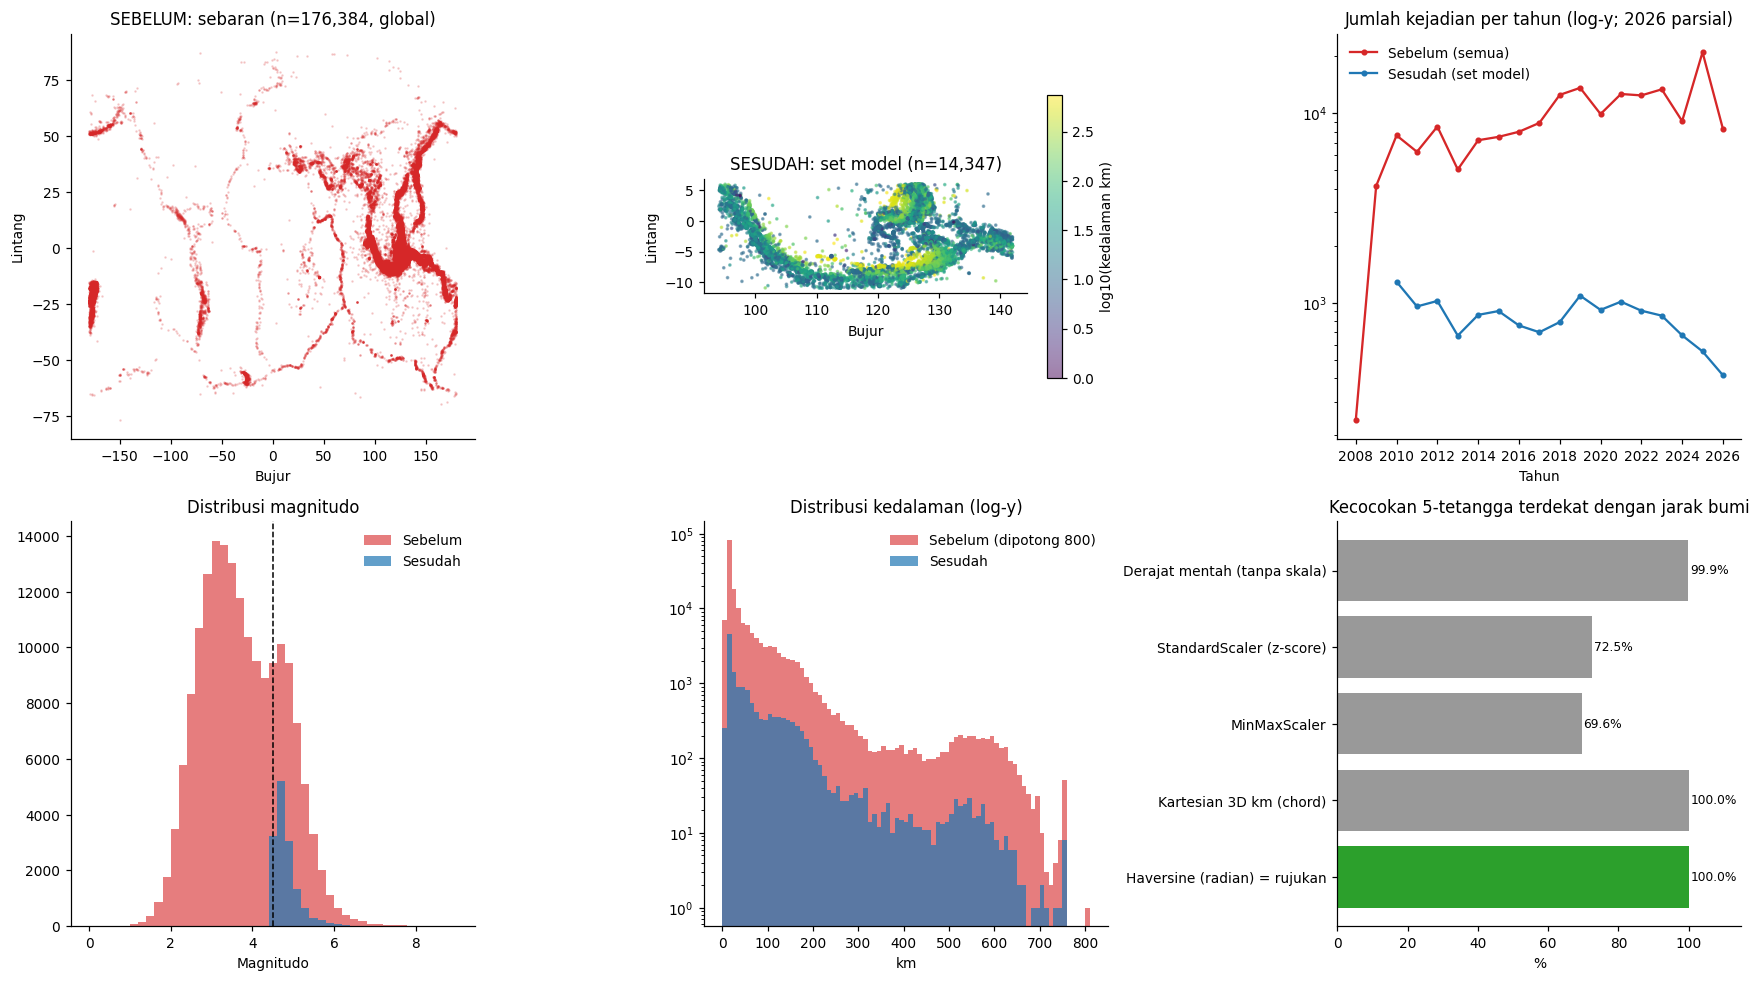

In [11]:
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
rawv = raw[["latitude", "longitude", "magnitude", "depth", "datetime"]].copy()
rawv["datetime"] = pd.to_datetime(rawv["datetime"], utc=True, format="ISO8601")

# (a)(b) peta
ax[0, 0].scatter(rawv.longitude, rawv.latitude, s=.3, alpha=.25, color="#d62728", rasterized=True)
ax[0, 0].set_title(f"SEBELUM: sebaran (n={len(rawv):,}, global)"); ax[0, 0].set_xlabel("Bujur"); ax[0, 0].set_ylabel("Lintang")
sc = ax[0, 1].scatter(model.longitude, model.latitude, c=np.log10(model.depth.clip(lower=1)), s=2, alpha=.5, cmap="viridis", rasterized=True)
ax[0, 1].set_title(f"SESUDAH: set model (n={len(model):,})"); ax[0, 1].set_xlabel("Bujur"); ax[0, 1].set_ylabel("Lintang"); ax[0, 1].set_aspect("equal")
plt.colorbar(sc, ax=ax[0, 1], shrink=.7, label="log10(kedalaman km)")

# (c) per tahun
yb = rawv.groupby(rawv.datetime.dt.year).size(); ya = model.groupby(model.datetime.dt.year).size()
ax[0, 2].plot(yb.index, yb.values, marker="o", ms=3, color="#d62728", label="Sebelum (semua)")
ax[0, 2].plot(ya.index, ya.values, marker="o", ms=3, color="#1f77b4", label="Sesudah (set model)")
ax[0, 2].xaxis.set_major_locator(MaxNLocator(integer=True)); ax[0, 2].set_yscale("log"); ax[0, 2].set_title("Jumlah kejadian per tahun (log-y; 2026 parsial)"); ax[0, 2].legend(frameon=False); ax[0, 2].set_xlabel("Tahun")

# (d) magnitudo
bins = np.arange(0, 9.2, .2)
ax[1, 0].hist(rawv.magnitude.dropna(), bins=bins, alpha=.6, color="#d62728", label="Sebelum")
ax[1, 0].hist(model.magnitude.dropna(), bins=bins, alpha=.7, color="#1f77b4", label="Sesudah")
ax[1, 0].axvline(MC_THRESHOLD, color="k", ls="--", lw=1); ax[1, 0].set_title("Distribusi magnitudo"); ax[1, 0].legend(frameon=False); ax[1, 0].set_xlabel("Magnitudo")

# (e) kedalaman
bins = np.arange(0, 820, 10)
ax[1, 1].hist(rawv.depth.clip(upper=800), bins=bins, alpha=.6, color="#d62728", label="Sebelum (dipotong 800)")
ax[1, 1].hist(model.depth, bins=bins, alpha=.7, color="#1f77b4", label="Sesudah")
ax[1, 1].set_yscale("log"); ax[1, 1].set_title("Distribusi kedalaman (log-y)"); ax[1, 1].legend(frameon=False); ax[1, 1].set_xlabel("km")

# (f) kesetiaan jarak
f = fidelity["kecocokan 5-tetangga (%)"]
ax[1, 2].barh(f.index[::-1], f.values[::-1], color=["#2ca02c" if "Haversine" in i else "#999999" for i in f.index[::-1]])
for i, v in enumerate(f.values[::-1]): ax[1, 2].text(v + .5, i, f"{v:.1f}%", va="center", fontsize=8)
ax[1, 2].set_xlim(0, 115); ax[1, 2].set_title("Kecocokan 5-tetangga terdekat dengan jarak bumi"); ax[1, 2].set_xlabel("%")

plt.tight_layout(); plt.savefig(f"{OUT_DIR}/perbandingan_sebelum_sesudah.png", dpi=130); plt.show()

## 10. Validasi kesiapan dan penyimpanan hasil

Uji berikut memastikan matriks fitur valid dan dapat diproses struktur data yang dipakai DBSCAN (`BallTree` + haversine). Ini hanya uji kesiapan; **penentuan `eps` dan `min_samples` adalah tahap berikutnya**.

In [12]:
# --- Uji kesiapan ---
assert X_haversine.shape == (len(model), 2) and X_3d_km.shape == (len(model), 3)
assert np.isfinite(X_haversine).all() and np.isfinite(X_3d_km).all()
assert (np.abs(X_haversine[:, 0]) <= np.pi / 2).all(), "latitude (radian) di luar [-pi/2, pi/2]"
assert model["eventID"].is_unique and not model.duplicated(["datetime", "latitude", "longitude"]).any()
assert model["magnitude"].min() >= MC_THRESHOLD and model["datetime"].min() >= pd.Timestamp(START_DATE, tz="UTC")

tree = BallTree(X_haversine, metric="haversine")
cnt = tree.query_radius(X_haversine[:500], r=eps_km_to_rad(50), count_only=True)
print("BallTree haversine berfungsi. Rata-rata tetangga dalam 50 km (uji 500 titik):", round(cnt.mean(), 1))

# --- Simpan semua keluaran ---
model_cols = ["eventID", "datetime", "latitude", "longitude", "depth", "magnitude", "mag_type",
              "phasecount", "azimuth_gap", "location", "agency", "has_focal_mechanism"]
model[model_cols].to_csv(f"{OUT_DIR}/gempa_siap_dbscan.csv", index=False)
df.to_csv(f"{OUT_DIR}/gempa_bersih_semua_baris.csv", index=False)          # semua baris + flag + exclusion_reason
removed_log.to_csv(f"{OUT_DIR}/log_baris_dihapus.csv", index=False)
waterfall.to_csv(f"{OUT_DIR}/log_waterfall.csv", index=False)
comparison.to_csv(f"{OUT_DIR}/perbandingan_sebelum_sesudah.csv")
np.save(f"{OUT_DIR}/X_haversine_rad.npy", X_haversine)
np.save(f"{OUT_DIR}/X_3d_km.npy", X_3d_km)
print("Tersimpan di", OUT_DIR, ":", sorted(os.listdir(OUT_DIR)))

if IN_COLAB:
    import shutil
    from google.colab import files
    shutil.make_archive("/content/hasil_preprocessing", "zip", OUT_DIR)
    files.download("/content/hasil_preprocessing.zip")

BallTree haversine berfungsi. Rata-rata tetangga dalam 50 km (uji 500 titik): 83.6
Tersimpan di /content/hasil_preprocessing : ['X_3d_km.npy', 'X_haversine_rad.npy', 'analisis_kelengkapan_katalog.png', 'gempa_bersih_semua_baris.csv', 'gempa_siap_dbscan.csv', 'log_baris_dihapus.csv', 'log_waterfall.csv', 'perbandingan_sebelum_sesudah.csv', 'perbandingan_sebelum_sesudah.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
import shutil
from google.colab import files

shutil.make_archive("/content/hasil_preprocessing", "zip", "/content/hasil_preprocessing")
files.download("/content/hasil_preprocessing.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Ringkasan: informasi apa yang dijaga?

- **Tidak ada baris yang dihapus diam-diam.** Hanya near-duplicate yang dihapus (tercatat di `log_baris_dihapus.csv`). Baris lain hanya diberi alasan di `exclusion_reason` pada `gempa_bersih_semua_baris.csv`.
- **Tidak ada nilai yang dikarang.** Koordinat dan magnitudo tidak diimputasi; yang kosong diberi label `Unknown` atau penanda.
- **Semua gempa M>=6 di wilayah dan periode studi dipertahankan** (di-`assert` pada sel penyaringan).
- **Informasi blok mekanisme fokal** diringkas menjadi `has_focal_mechanism`, bukan dibuang.
- **Geometri bumi tidak diubah**: tidak memakai z-score pada koordinat.
- **Parameter terbuka**: wilayah, periode, dan ambang Mc dapat diubah di sel Konfigurasi, lalu seluruh notebook dijalankan ulang untuk analisis sensitivitas.

**Tahap berikutnya (belum dilakukan):** menentukan `eps` dan `min_samples` (grafik k-distance), menjalankan DBSCAN, dan mengevaluasi klaster.